In [ ]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, confusion_matrix , classification_report

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
df = pd.read_csv('/Customer_Churn_Dataset.csv')

In [ ]:
df.head()

,Age,Monthly_Bill,Tenure,Support_Calls,Churn
0,34,1907,3,1,Yes
1,21,923,5,4,Yes
2,39,1708,40,6,Yes
3,35,1730,11,2,No
4,55,1243,8,2,No


In [ ]:
df.tail()

,Age,Monthly_Bill,Tenure,Support_Calls,Churn
995,54,816,58,0,No
996,63,1524,32,6,Yes
997,63,1865,9,6,Yes
998,31,1655,29,4,No
999,52,1727,44,4,No


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Age            1000 non-null   int64 
 1   Monthly_Bill   1000 non-null   int64 
 2   Tenure         1000 non-null   int64 
 3   Support_Calls  1000 non-null   int64 
 4   Churn          1000 non-null   object
dtypes: int64(4), object(1)
memory usage: 39.2+ KB


In [ ]:
df.shape

(1000, 5)

In [ ]:
df.columns

Index(['Age', 'Monthly_Bill', 'Tenure', 'Support_Calls', 'Churn'], dtype='object')

In [ ]:
df.describe()

,Age,Monthly_Bill,Tenure,Support_Calls
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,41.385000,1162.122000,30.478000,4.051000
std,13.792208,477.566872,17.141626,2.535513
min,18.000000,301.000000,1.000000,0.000000
25%,29.000000,752.750000,17.000000,2.000000
50%,41.000000,1166.000000,31.000000,4.000000
75%,54.000000,1571.500000,45.000000,6.000000
max,65.000000,1999.000000,60.000000,8.000000


In [ ]:
df.isnull().sum()

,0
Age,0
Monthly_Bill,0
Tenure,0
Support_Calls,0
Churn,0


In [ ]:
df.dropna(inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop_duplicates(inplace=True)

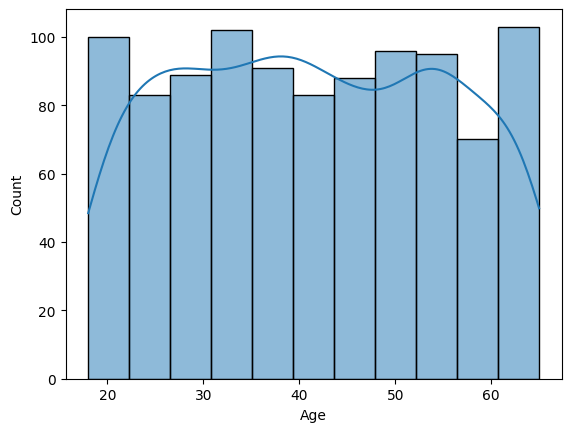

In [ ]:
sns.histplot(df["Age"],kde=True)
plt.show()

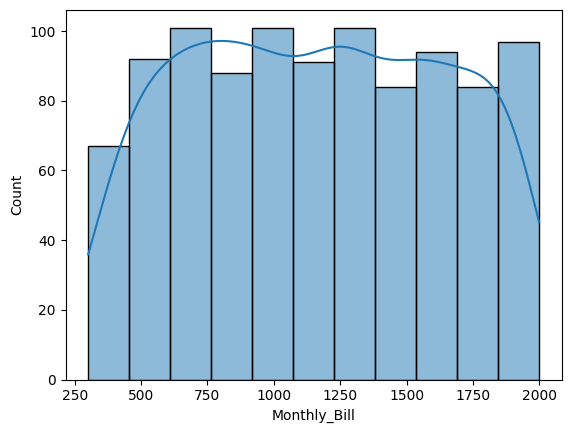

In [ ]:
sns.histplot(df["Monthly_Bill"],kde=True)
plt.show()

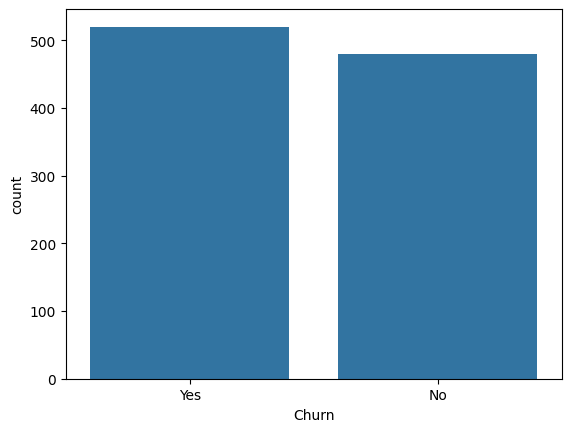

In [ ]:
sns.countplot(x="Churn",data=df)
plt.show()

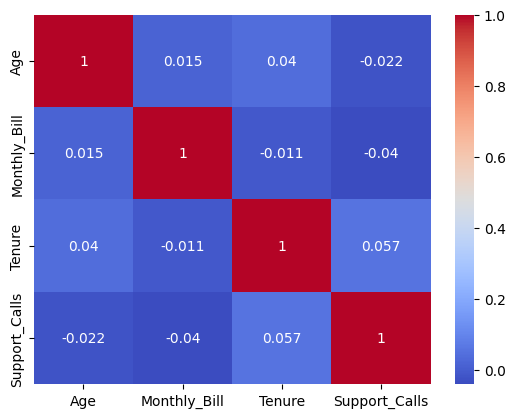

In [ ]:
sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap = 'coolwarm')
plt.show()

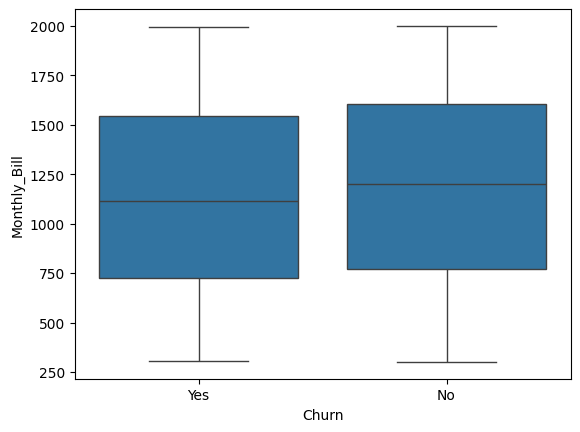

In [ ]:
sns.boxplot(x="Churn",
            y="Monthly_Bill",
            data=df)

plt.show()

In [ ]:
le = LabelEncoder()
df["Churn"] = le.fit_transform(df["Churn"])

In [ ]:
X= df.drop("Churn",axis=1)
y = df['Churn']

In [ ]:
X_train, X_test , y_train , y_test = train_test_split(X,y,test_size =0.2,random_state=42)

In [ ]:
lr = LogisticRegression()
lr.fit(X_train,y_train)

LogisticRegression()

In [ ]:
y_lr_pred = lr.predict(X_test)
print(y_lr_pred)

[1 1 1 1 1 1 0 0 1 1 0 1 0 0 0 1 1 1 1 1 1 1 0 1 0 0 0 0 0 1 0 0 0 0 0 1 1
 1 1 0 1 0 0 0 1 1 1 0 1 1 1 1 1 0 0 0 1 0 1 0 0 0 1 1 0 1 0 1 1 0 0 1 1 1
 0 1 1 0 1 0 1 1 1 0 0 0 1 0 0 1 0 1 1 1 0 1 0 0 0 1 1 1 1 1 1 0 0 0 1 1 0
 1 1 0 0 0 1 1 1 1 0 1 1 1 1 1 0 0 1 0 1 0 0 0 1 0 1 1 0 0 0 1 0 1 0 0 0 1
 0 1 1 0 1 1 1 1 0 1 0 1 1 1 0 1 1 0 0 0 0 1 0 1 1 1 0 1 0 0 0 1 0 1 1 0 0
 1 0 1 0 0 1 0 0 0 0 1 0 1 0 0]


In [ ]:
accuracy_score(y_test,y_lr_pred)

0.835

In [ ]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train,y_train)

DecisionTreeClassifier(random_state=42)

In [ ]:
y_dt_pred= dt.predict(X_test)
print(y_dt_pred)

[0 1 1 1 1 1 1 0 1 0 0 0 1 0 0 1 1 1 1 1 0 1 0 1 0 1 0 0 0 1 0 0 0 0 0 0 0
 1 1 1 1 0 0 0 1 1 1 0 0 1 0 1 0 0 0 0 1 0 1 0 0 0 1 1 0 0 0 0 1 0 0 1 1 0
 0 0 1 0 1 0 1 1 1 1 0 0 0 0 0 1 0 1 0 1 0 1 0 0 0 1 1 1 0 1 1 0 0 0 1 1 0
 1 1 0 0 0 1 1 1 1 0 1 1 1 1 1 0 0 1 0 0 1 0 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1
 0 1 1 1 1 1 1 1 0 0 1 1 1 1 0 1 1 0 0 0 0 1 0 1 1 1 0 1 0 1 0 0 0 1 0 0 0
 1 0 1 0 0 0 0 1 1 0 1 0 1 0 0]


In [ ]:
accuracy_score(y_test,y_dt_pred)

1.0

In [ ]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train,y_train)


RandomForestClassifier(random_state=42)

In [ ]:
y_rf_pred = rf.predict(X_test)
print(y_rf_pred)


[0 1 1 1 1 1 1 0 1 0 0 0 1 0 0 1 1 1 1 1 0 1 0 1 0 1 0 0 0 1 0 0 0 0 0 0 0
 1 1 1 1 0 0 0 1 1 1 0 0 1 0 1 0 0 0 0 1 0 1 0 0 0 1 1 0 0 0 0 1 0 0 1 1 0
 0 0 1 0 1 0 1 1 1 1 0 0 0 0 0 1 0 1 0 1 0 1 0 0 0 1 1 1 0 1 1 0 0 0 1 1 0
 1 1 0 0 0 1 1 1 1 0 1 1 1 1 1 0 0 1 0 0 1 0 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1
 0 1 1 1 1 1 1 1 0 0 1 1 1 1 0 1 1 0 0 0 0 1 0 1 1 1 0 1 0 1 0 0 0 1 0 0 0
 1 0 1 0 0 0 0 1 1 0 1 0 1 0 0]


In [ ]:
accuracy_score(y_test,y_rf_pred)

1.0

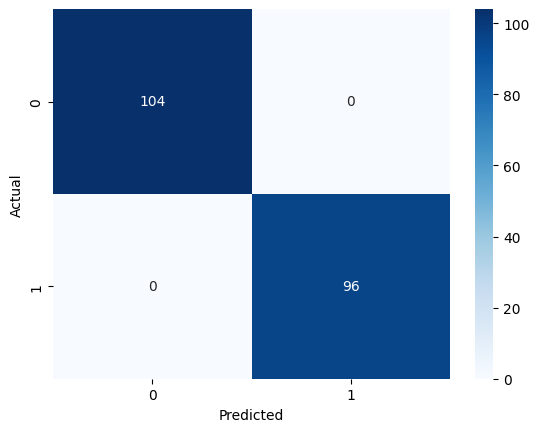

In [ ]:
cm = confusion_matrix(y_test,y_rf_pred)

sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()